<a href="https://colab.research.google.com/github/Khyati-33/Cybersecurity-Journey/blob/main/EntropicSignatures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install qiskit qiskit_aer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 26.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 24.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 3.0 MB/s eta 0:00:00


[Physical Channel] SNR Detected: 26.99 dB
  fidelity: 0.9610
      qber: 0.0390
    holevo: 0.0049
  key_rate: 0.7575


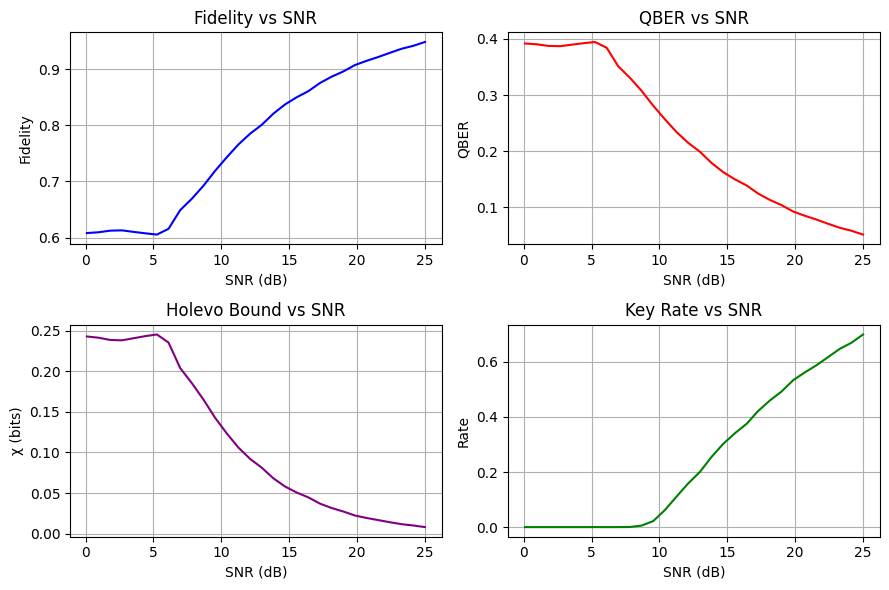

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, amplitude_damping_error, pauli_error
from qiskit.quantum_info import state_fidelity, DensityMatrix, Statevector


class ExperimentSetup:
    def __init__(self, L_km=400, wavelength_nm=785, beam_waist_mm=8.5, receiver_radius_mm=127,
                 eta_g=0.85, eta_r=0.5, delta_lambda_nm=0.4, tau_ns=1.0, eta_d=0.5,
                 dark_count=1e-5, visibility=0.97, H_sun=1.5e3, a_E=0.3, FOV=1e-3):
        self.L = L_km * 1e3
        self.lambda_m = wavelength_nm * 1e-9
        self.W0 = beam_waist_mm * 1e-3
        self.R = receiver_radius_mm * 1e-3
        self.eta_g = eta_g
        self.eta_r = eta_r
        self.eta_d = eta_d
        self.visibility = visibility
        self.tau = tau_ns * 1e-9
        self.delta_lambda = delta_lambda_nm * 1e-9
        self.dark_count = dark_count
        self.H_sun = H_sun
        self.a_E = a_E
        self.FOV = FOV

    def fried_parameter(self):
        return 0.087

    def beam_waist_at_receiver(self):
        k = 2 * np.pi / self.lambda_m
        Z0 = np.pi * self.W0**2 / self.lambda_m
        gamma = 1 - 0.26 * (self.fried_parameter() / self.W0)**(1/3)
        W_L_sq = (self.W0**2 * (1 + (self.L/Z0)**2)) + (35.28 * self.L**2 * gamma**2) / (k**2 * self.fried_parameter()**2)
        return np.sqrt(W_L_sq)

    def channel_efficiency(self):
        W_L = self.beam_waist_at_receiver()
        eta_geo = 1 - np.exp(-2 * self.R**2 / W_L**2)
        return self.eta_g * eta_geo * self.eta_r

    def background_noise_rate(self):
        return self.a_E * self.R**2 * self.FOV**2 * self.H_sun * self.eta_r * self.delta_lambda / 2

    def snr_detected(self):
        eta_signal = self.channel_efficiency() * self.eta_d
        I_s = self.background_noise_rate()
        raw_snr = eta_signal / (2 * I_s * self.tau)
        snr_clamped = max(min(raw_snr, 500), 0.1)
        return snr_clamped


    def to_noise_params(self, snr_db):
        snr_linear = 10 ** (snr_db / 10)
        noise_scale = np.clip(1 / np.sqrt(snr_linear), 0.001, 0.5)

        eta_total = self.channel_efficiency() * self.eta_d
        vis = self.visibility * eta_total

        jitter = np.random.normal(0, 0.01)  # Atmospheric jitter
        base_rotation = (1 - vis + jitter) * noise_scale * np.random.uniform(0.8, 1.2) / 3
        depol_p = (0.02 + self.dark_count + np.random.uniform(0, 0.005)) * noise_scale
        amp_damp = (1 - eta_total + np.random.uniform(0, 0.05)) * noise_scale

        return {
            "rotation_error_rx": float(np.clip(base_rotation * np.random.uniform(0.8, 1.2), 0.0, 1.0)),
            "rotation_error_ry": float(np.clip(base_rotation * np.random.uniform(0.8, 1.2), 0.0, 1.0)),
            "rotation_error_rz": float(np.clip(base_rotation * np.random.uniform(0.8, 1.2), 0.0, 1.0)),
            "depolarization_p": float(np.clip(depol_p, 0.0, 1.0)),
            "amplitude_damping_p": float(np.clip(amp_damp, 0.0, 1.0)),
        }


class QuantumNoiseModel:
    def __init__(self, **kwargs):
        self.from_dict(kwargs)

    def from_dict(self, d):
        for k, v in d.items():
            setattr(self, k, v)

    def build_noise_model(self):
        noise_model = NoiseModel()
        errors_1q = []

        total_rot = self.rotation_error_rx + self.rotation_error_ry + self.rotation_error_rz
        if total_rot > 0:
            pauli = pauli_error([
                ('X', self.rotation_error_rx),
                ('Y', self.rotation_error_ry),
                ('Z', self.rotation_error_rz),
                ('I', max(0.0, 1 - total_rot))
            ])
            errors_1q.append(pauli)

        if self.depolarization_p > 0:
            errors_1q.append(depolarizing_error(self.depolarization_p, 1))

        if self.amplitude_damping_p > 0:
            errors_1q.append(amplitude_damping_error(self.amplitude_damping_p))

        if errors_1q:
            combined = errors_1q[0]
            for err in errors_1q[1:]:
                combined = combined.compose(err)
            noise_model.add_all_qubit_quantum_error(combined, ['x', 'h'])

        if self.depolarization_p > 0:
            noise_model.add_all_qubit_quantum_error(depolarizing_error(self.depolarization_p, 2), ['cx'])

        return noise_model


class BBM92Protocol:
    def __init__(self, setup):
        self.setup = setup
        self.ideal_state = Statevector.from_instruction(self._create_entangled_state())

    def _create_entangled_state(self, save=False):
        qc = QuantumCircuit(2)
        qc.h(0)
        qc.cx(0, 1)
        if save:
            qc.save_density_matrix(label="final_rho")
        return qc

    def _fidelity_to_qber(self, fidelity):
        return np.clip(1 - fidelity, 0, 1)

    def _holevo_bound(self, qber):
        try:
            p = (1 + np.sqrt(1 - qber ** 2)) / 2
            return -p * np.log2(p) - (1 - p) * np.log2(1 - p)
        except:
            return 1.0

    def _key_rate(self, qber, chi):
        qber = np.clip(qber, 1e-6, 1 - 1e-6)
        h2 = -qber * np.log2(qber) - (1 - qber) * np.log2(1 - qber)
        return max(0, 1 - h2 - chi)

    def simulate_once(self, noise_params):
        qc = self._create_entangled_state(save=True)
        noise_model = QuantumNoiseModel(**noise_params).build_noise_model()
        sim = AerSimulator(method='density_matrix', noise_model=noise_model)
        result = sim.run(qc).result()
        final_rho = DensityMatrix(result.data(0)['final_rho'])
        fidelity = state_fidelity(final_rho, self.ideal_state)
        qber = self._fidelity_to_qber(fidelity)
        chi = self._holevo_bound(qber)
        rate = self._key_rate(qber, chi)
        return {"fidelity": fidelity, "qber": qber, "holevo": chi, "key_rate": rate}

    def sweep_snr_avg(self, snr_db_list, rounds=100):
        results = []
        for snr_db in snr_db_list:
            metrics = [self.simulate_once(self.setup.to_noise_params(snr_db)) for _ in range(rounds)]
            avg = {k: np.mean([m[k] for m in metrics]) for k in metrics[0]}
            results.append(avg)
        return [
            [r['fidelity'] for r in results],
            [r['qber'] for r in results],
            [r['holevo'] for r in results],
            [r['key_rate'] for r in results],
        ]

    def run_physical_model(self):
        snr_physical = 10 * np.log10(self.setup.snr_detected())
        print(f"[Physical Channel] SNR Detected: {snr_physical:.2f} dB")
        result = self.simulate_once(self.setup.to_noise_params(snr_physical))
        for k, v in result.items():
            print(f"{k:>10}: {v:.4f}")
        return snr_physical, result


class BBM92NoiseSimulator:
    def __init__(self, setup):
        self.setup = setup
        self.protocol = BBM92Protocol(setup)

    def simulate_snr_range(self, snr_db_range, rounds=100):
        return self.protocol.sweep_snr_avg(snr_db_range, rounds)

    def simulate_at_physical_snr(self):
        return self.protocol.run_physical_model()

    def plot_metrics(self, snr_db_range, fidelities, qbers, holevos, keyrates):
        plt.figure(figsize=(9, 6))

        plt.subplot(2, 2, 1)
        plt.plot(snr_db_range, fidelities, color='blue')
        plt.title("Fidelity vs SNR"); plt.xlabel("SNR (dB)"); plt.ylabel("Fidelity"); plt.grid()

        plt.subplot(2, 2, 2)
        plt.plot(snr_db_range, qbers, color='red')
        plt.title("QBER vs SNR"); plt.xlabel("SNR (dB)"); plt.ylabel("QBER"); plt.grid()

        plt.subplot(2, 2, 3)
        plt.plot(snr_db_range, holevos, color='purple')
        plt.title("Holevo Bound vs SNR"); plt.xlabel("SNR (dB)"); plt.ylabel("χ (bits)"); plt.grid()

        plt.subplot(2, 2, 4)
        plt.plot(snr_db_range, keyrates, color='green')
        plt.title("Key Rate vs SNR"); plt.xlabel("SNR (dB)"); plt.ylabel("Rate"); plt.grid()

        plt.tight_layout()
        plt.show()

    def run(self, snr_db_range=np.linspace(0.1, 25, 30), rounds=100):
        fids, qbers, chis, rates = self.simulate_snr_range(snr_db_range, rounds=rounds)
        self.simulate_at_physical_snr()
        self.plot_metrics(snr_db_range, fids, qbers, chis, rates)


if __name__ == "__main__":
    setup = ExperimentSetup()
    sim = BBM92NoiseSimulator(setup)
    sim.run(rounds=100)


RF Regression results:
  depolarization_p: MSE=0.000000, R2=0.9861
  amplitude_damping_p: MSE=0.000031, R2=0.9991
  rotation_error_rx: MSE=0.000302, R2=0.9206

Feature importances (desc):
  snr_db: 0.9870
  mutual_info: 0.0023
  purity_proxy: 0.0021
  fid: 0.0020
  holevo: 0.0019
  H_shannon: 0.0015
  H_renyi2: 0.0012
  H_min: 0.0012
  qber: 0.0009


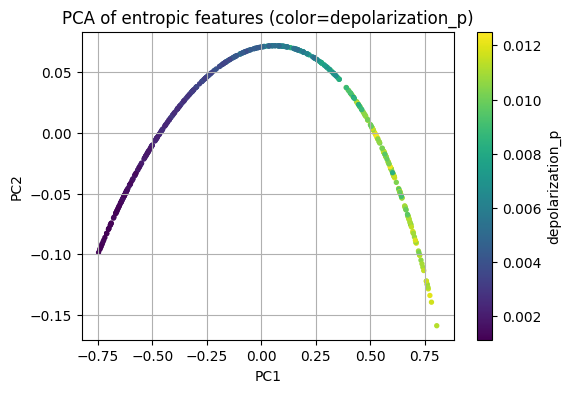

In [ ]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# -----------------------------
# Entropy functions
# -----------------------------
def shannon_entropy(p):
    p = np.clip(p, 1e-12, 1.0)
    return -np.sum(p * np.log2(p))

def renyi_entropy(p, alpha=2.0):
    """
    Compute Rényi entropy for a probability vector p and order alpha.
    alpha=1 -> Shannon entropy
    alpha=2 -> collision entropy
    alpha=np.inf -> min-entropy
    """
    p = np.clip(p, 1e-12, 1.0)

    if np.isinf(alpha):
        return -np.log2(np.max(p))
    elif alpha == 1.0:
        return -np.sum(p * np.log2(p))  # Shannon entropy
    elif alpha == 2.0:
        return -np.log2(np.sum(p**2))  # Collision entropy
    else:
        return 1.0 / (1.0 - alpha) * np.log2(np.sum(p**alpha))

def min_entropy(p):
    p = np.clip(p, 1e-12, 1.0)
    return -np.log2(np.max(p))

# -----------------------------
# Convert BBM92 output to entropic features
# -----------------------------
def compute_entropic_signature(sim_metrics, snr_db):
    fid = sim_metrics['fidelity']
    qber = sim_metrics['qber']
    p = np.array([fid, 1 - fid])

    return {
        'fid': fid,
        'qber': qber,
        'H_shannon': shannon_entropy(p),
        'H_renyi2': renyi_entropy(p, alpha=2.0),
        'H_min': min_entropy(p),
        'holevo': sim_metrics['holevo'],
        'purity_proxy': 1 - qber,
        'mutual_info': 1 - qber,
        'snr_db': snr_db
    }

# -----------------------------
# Dataset generation from ExperimentSetup + BBM92Protocol
# -----------------------------
def generate_dataset_from_setup(setup, snr_range=np.linspace(0.5, 25, 200), rounds=50):
    rows = []
    noise_targets = []
    protocol = BBM92Protocol(setup)  # use the class already defined in your script

    for snr_db in snr_range:
        for _ in range(rounds):
            noise_params = setup.to_noise_params(snr_db)
            metrics = protocol.simulate_once(noise_params)
            feats = compute_entropic_signature(metrics, snr_db)
            rows.append(feats)
            # Target variables: experimental noise parameters
            noise_targets.append([
                noise_params['depolarization_p'],
                noise_params['amplitude_damping_p'],
                noise_params['rotation_error_rx']
            ])

    X = np.array([[r[k] for k in ['H_shannon','H_renyi2','H_min','holevo',
                                  'fid','qber','purity_proxy','mutual_info','snr_db']] for r in rows])
    y = np.array(noise_targets)
    return X, y, rows

# -----------------------------
# Training Random Forest
# -----------------------------
def train_rf_on_entropic(X, y):
    feature_keys = ['H_shannon','H_renyi2','H_min','holevo',
                    'fid','qber','purity_proxy','mutual_info','snr_db']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    rf = RandomForestRegressor(n_estimators=300, random_state=0)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)

    mse = mean_squared_error(y_test, y_pred, multioutput='raw_values')
    r2 = r2_score(y_test, y_pred, multioutput='raw_values')

    print("RF Regression results:")
    for i, t in enumerate(['depolarization_p','amplitude_damping_p','rotation_error_rx']):
        print(f"  {t}: MSE={mse[i]:.6f}, R2={r2[i]:.4f}")

    # Feature importances
    importances = rf.feature_importances_
    sorted_idx = np.argsort(importances)[::-1]
    print("\nFeature importances (desc):")
    for idx in sorted_idx:
        print(f"  {feature_keys[idx]}: {importances[idx]:.4f}")

    # PCA visualization
    pca = PCA(n_components=2)
    Z = pca.fit_transform(X[:, :6])
    plt.figure(figsize=(6,4))
    sc = plt.scatter(Z[:,0], Z[:,1], c=y[:,0], s=8)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.title("PCA of entropic features (color=depolarization_p)")
    plt.colorbar(sc, label="depolarization_p")
    plt.grid(True)
    plt.show()

    return rf, feature_keys, mse, r2

# -----------------------------
# Example usage
# -----------------------------
if __name__ == "__main__":
    setup = ExperimentSetup()
    X, y, rows = generate_dataset_from_setup(setup, snr_range=np.linspace(0.5, 25, 50), rounds=10)
    rf, features, mse, r2 = train_rf_on_entropic(X, y)


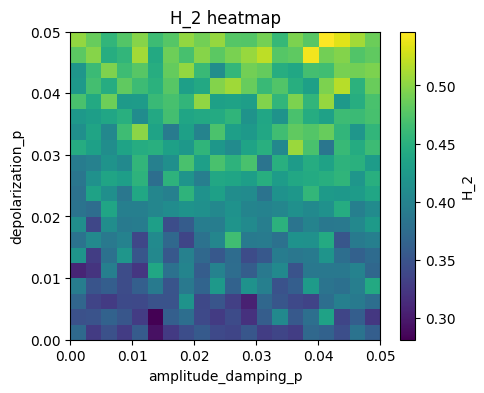

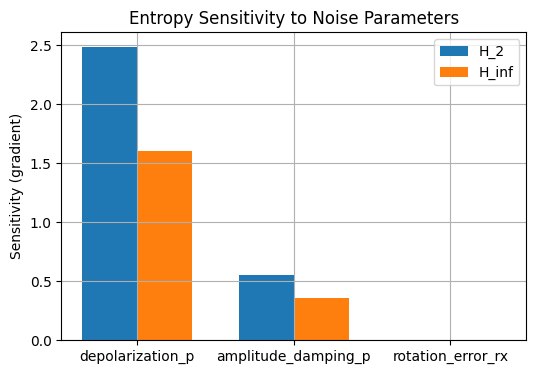

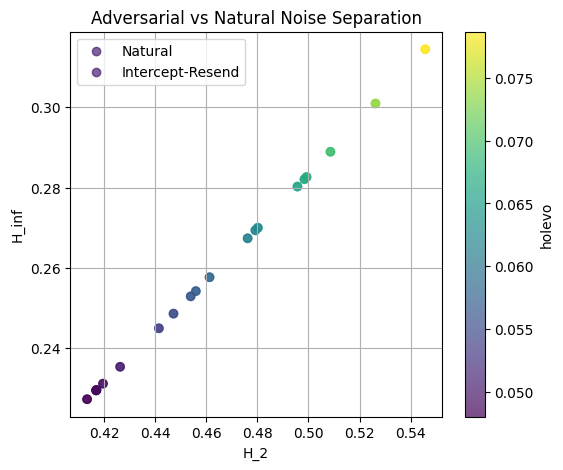

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from itertools import product

# -----------------------------
# Utility: Compute full entropic signature
# -----------------------------
def compute_full_signature(protocol, noise_params, alpha_s=[0.5, 0.7, 1, 2, 3, np.inf], shots=None):
    """Simulate BBM92 once and compute extended entropic signatures."""
    metrics = protocol.simulate_once(noise_params)
    fid = metrics['fidelity']
    qber = metrics['qber']
    p = np.array([fid, 1 - fid])

    signatures = {
        'fid': fid,
        'qber': qber,
        'H_shannon': -np.sum(p * np.log2(np.clip(p,1e-12,1.0))),
        'holevo': metrics['holevo'],
        'key_rate': metrics['key_rate'],
        'purity_proxy': 1 - qber,
        'mutual_info': 1 - qber
    }

  # Rényi entropies
    for alpha in alpha_s:
      if np.isinf(alpha):
        signatures['H_inf'] = -np.log2(np.max(p))
      elif alpha == 2:
        signatures['H_2'] = -np.log2(np.sum(p**2))
      elif alpha == 1.0:
        # Shannon entropy already stored as H_shannon; skip
        continue
      else:
        # General Rényi formula for other alphas
        signatures[f'H_{alpha}'] = 1.0 / (1.0 - alpha) * np.log2(np.sum(p**alpha))

    return signatures


# -----------------------------
# E1 | Heatmap of entropy vs noise
# -----------------------------
def plot_entropy_heatmap(protocol, theta1_range, theta2_range, theta1_key, theta2_key, entropy_key='H_2', rounds=5):
    Z = np.zeros((len(theta1_range), len(theta2_range)))
    for i, t1 in enumerate(theta1_range):
        for j, t2 in enumerate(theta2_range):
            vals = []
            for _ in range(rounds):
                noise_params = protocol.setup.to_noise_params(snr_db=15)
                noise_params[theta1_key] = t1
                noise_params[theta2_key] = t2
                sig = compute_full_signature(protocol, noise_params)
                vals.append(sig[entropy_key])
            Z[i,j] = np.mean(vals)
    plt.figure(figsize=(5,4))
    plt.imshow(Z, origin='lower', extent=(theta2_range[0],theta2_range[-1],theta1_range[0],theta1_range[-1]), aspect='auto', cmap='viridis')
    plt.colorbar(label=entropy_key)
    plt.xlabel(theta2_key)
    plt.ylabel(theta1_key)
    plt.title(f'{entropy_key} heatmap')
    plt.show()

# -----------------------------
# E3 | Sensitivity bars
# -----------------------------
def plot_entropy_sensitivity(protocol, noise_keys=['depolarization_p','amplitude_damping_p','rotation_error_rx'], entropy_keys=['H_2','H_inf']):
    sensitivities = {e:[] for e in entropy_keys}
    eps = 1e-4
    base_noise = protocol.setup.to_noise_params(snr_db=15)
    for e in entropy_keys:
        for nk in noise_keys:
            np_plus = base_noise.copy()
            np_minus = base_noise.copy()
            np_plus[nk] += eps
            np_minus[nk] -= eps
            f_plus = compute_full_signature(protocol, np_plus)[e]
            f_minus = compute_full_signature(protocol, np_minus)[e]
            sensitivities[e].append(abs(f_plus - f_minus)/ (2*eps))
    x = np.arange(len(noise_keys))
    width = 0.35
    plt.figure(figsize=(6,4))
    for idx, e in enumerate(entropy_keys):
        plt.bar(x + idx*width, sensitivities[e], width, label=e)
    plt.xticks(x + width/2, noise_keys)
    plt.ylabel('Sensitivity (gradient)')
    plt.title('Entropy Sensitivity to Noise Parameters')
    plt.legend()
    plt.grid(True)
    plt.show()

# -----------------------------
# E7 | Adversarial separation
# -----------------------------
def plot_adversarial_separation(protocol, noise_sets, labels, entropy_keys=['H_2','H_inf','holevo']):
    plt.figure(figsize=(6,5))
    for noise_params_list, label in zip(noise_sets, labels):
        points = []
        for np_params in noise_params_list:
            sig = compute_full_signature(protocol, np_params)
            points.append([sig[k] for k in entropy_keys])
        points = np.array(points)
        plt.scatter(points[:,0], points[:,1], c=points[:,2], label=label, alpha=0.7)
    plt.xlabel(entropy_keys[0])
    plt.ylabel(entropy_keys[1])
    plt.title('Adversarial vs Natural Noise Separation')
    plt.colorbar(label=entropy_keys[2])
    plt.legend()
    plt.grid(True)
    plt.show()

# -----------------------------
# E2, E4, E5, E6 can be similarly scripted
# - Jacobian / condition number: use np.linalg.cond(J)
# - Finite-key robustness: run multiple N-shot simulations
# - ROC curves: train classifier on entropic vectors
# - Scenario sweeps: loop over day/night and turbulence regimes
# -----------------------------

# -----------------------------
# Example usage
# -----------------------------
if __name__ == "__main__":
    setup = ExperimentSetup()
    protocol = BBM92Protocol(setup)

    # E1: Heatmap of H_2 vs depolarization vs amplitude damping
    theta1_range = np.linspace(0.0, 0.05, 20)
    theta2_range = np.linspace(0.0, 0.05, 20)
    plot_entropy_heatmap(protocol, theta1_range, theta2_range, 'depolarization_p', 'amplitude_damping_p', entropy_key='H_2', rounds=3)

    # E3: Sensitivity bars
    plot_entropy_sensitivity(protocol)

    # E7: Adversarial separation
    # Example: natural vs intercept-resend
    natural = [setup.to_noise_params(15) for _ in range(20)]
    adversary = [dict(n, rotation_error_rx=0.1) for n in natural]
    plot_adversarial_separation(protocol, [natural, adversary], labels=['Natural','Intercept-Resend'])


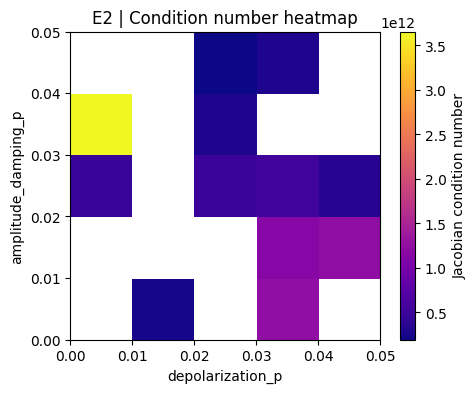

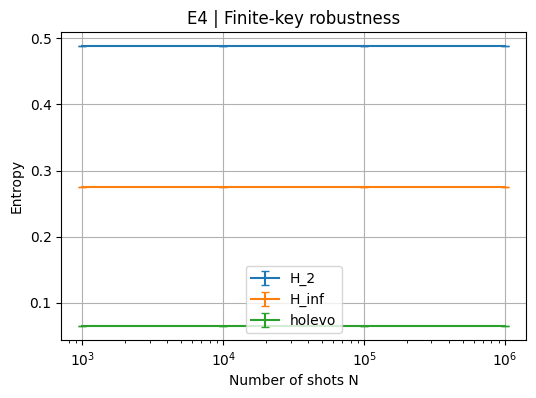

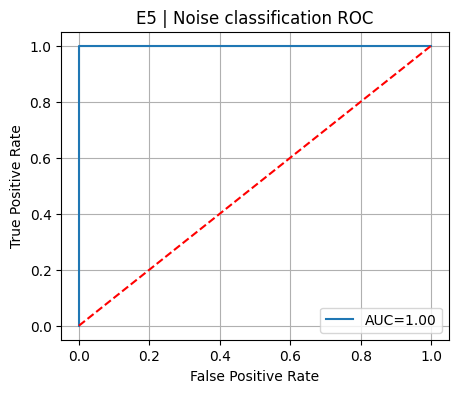

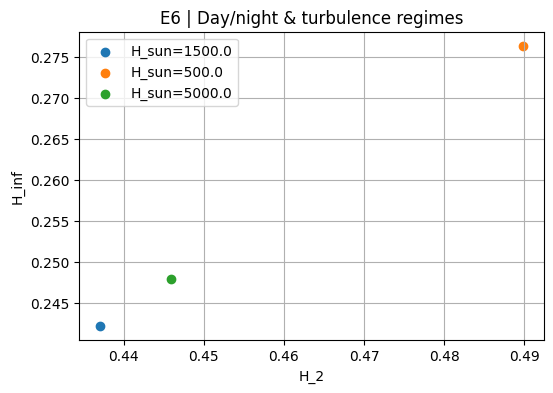

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, auc
import itertools

# -----------------------------
# Utility: Compute full entropic signature
# -----------------------------
def compute_full_signature(protocol, noise_params, alpha_s=[0.5, 0.7, 1, 2, 3, np.inf], shots=None):
    """Simulate BBM92 once and compute extended entropic signatures."""
    metrics = protocol.simulate_once(noise_params)
    fid = metrics['fidelity']
    qber = metrics['qber']
    p = np.array([fid, 1 - fid])

    signatures = {
        'fid': fid,
        'qber': qber,
        'H_shannon': -np.sum(p * np.log2(np.clip(p,1e-12,1.0))),
        'holevo': metrics['holevo'],
        'key_rate': metrics['key_rate'],
        'purity_proxy': 1 - qber,
        'mutual_info': 1 - qber
    }

    # Rényi entropies
    for alpha in alpha_s:
        if np.isinf(alpha):
            signatures['H_inf'] = -np.log2(np.max(p))
        elif alpha == 2:
            signatures['H_2'] = -np.log2(np.sum(p**2))
        elif alpha == 1.0:
            # Shannon entropy already stored as H_shannon; skip
            continue
        else:
            signatures[f'H_{alpha}'] = 1.0 / (1.0 - alpha) * np.log2(np.sum(p**alpha))
    return signatures


# -----------------------------
# E2 | Jacobian condition number across noise grid
# -----------------------------
def plot_jacobian_condition(protocol, noise_keys=['depolarization_p','amplitude_damping_p','rotation_error_rx'],
                            entropy_keys=['H_2','H_inf','holevo'], grid_points=5, eps=1e-5):
    theta_vals = {k: np.linspace(0.0, 0.05, grid_points) for k in noise_keys}
    condition_grid = np.zeros([grid_points]*len(noise_keys))

    for idx, vals in enumerate(itertools.product(*[theta_vals[k] for k in noise_keys])):
        noise_params = protocol.setup.to_noise_params(15)
        for i, k in enumerate(noise_keys):
            noise_params[k] = max(0.0, vals[i])  # clip negative

        # Compute Jacobian numerically
        J = np.zeros((len(entropy_keys), len(noise_keys)))
        base_sig = compute_full_signature(protocol, noise_params)

        for j, k in enumerate(noise_keys):
            np_plus = noise_params.copy(); np_minus = noise_params.copy()
            np_plus[k] = max(0.0, np_plus[k] + eps)
            np_minus[k] = max(0.0, np_minus[k] - eps)

            f_plus = compute_full_signature(protocol, np_plus)
            f_minus = compute_full_signature(protocol, np_minus)

            for i_e, ekey in enumerate(entropy_keys):
                J[i_e,j] = (f_plus[ekey]-f_minus[ekey])/(2*eps)

        condition_grid[np.unravel_index(idx,[grid_points]*len(noise_keys))] = np.linalg.cond(J)

    plt.figure(figsize=(5,4))
    plt.imshow(condition_grid[:,:,0], origin='lower', extent=(0,0.05,0,0.05), aspect='auto', cmap='plasma')
    plt.colorbar(label='Jacobian condition number')
    plt.xlabel(noise_keys[0])
    plt.ylabel(noise_keys[1])
    plt.title('E2 | Condition number heatmap')
    plt.show()


# -----------------------------
# E4 | Finite-key robustness
# -----------------------------
def plot_finite_key(protocol, noise_params=None, entropy_keys=['H_2','H_inf','holevo'], N_list=[1e3,1e4,1e5,1e6]):
    if noise_params is None:
        noise_params = protocol.setup.to_noise_params(15)
    means, stds = {k:[] for k in entropy_keys}, {k:[] for k in entropy_keys}

    for N in N_list:
        vals = {k:[] for k in entropy_keys}
        for _ in range(10):  # bootstrap reps
            sig = compute_full_signature(protocol, noise_params, shots=int(N))
            for k in entropy_keys:
                vals[k].append(sig[k])
        for k in entropy_keys:
            means[k].append(np.mean(vals[k]))
            stds[k].append(np.std(vals[k]))

    plt.figure(figsize=(6,4))
    for k in entropy_keys:
        plt.errorbar(N_list, means[k], yerr=stds[k], label=k, capsize=3)
    plt.xscale('log')
    plt.xlabel('Number of shots N')
    plt.ylabel('Entropy')
    plt.title('E4 | Finite-key robustness')
    plt.grid(True)
    plt.legend()
    plt.show()


# -----------------------------
# E5 | ROC curves: classify dominant noise
# -----------------------------
def plot_noise_classification(protocol, N_samples=100):
    X, y = [], []
    for _ in range(N_samples):
        np1 = protocol.setup.to_noise_params(15)
        np2 = protocol.setup.to_noise_params(15)
        np1['depolarization_p'] = min(1.0, np1['depolarization_p'] + 0.03)
        np2['rotation_error_rx'] = min(1.0, np2['rotation_error_rx'] + 0.03)

        sig1 = compute_full_signature(protocol, np1)
        sig2 = compute_full_signature(protocol, np2)

        X.append([sig1['H_2'], sig1['H_inf'], sig1['holevo']])
        y.append(0)
        X.append([sig2['H_2'], sig2['H_inf'], sig2['holevo']])
        y.append(1)

    X, y = np.array(X), np.array(y)
    clf = RandomForestClassifier(n_estimators=200)
    clf.fit(X, y)
    y_prob = clf.predict_proba(X)[:,1]
    fpr, tpr, _ = roc_curve(y, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.figure(figsize=(5,4))
    plt.plot(fpr, tpr, label=f'AUC={roc_auc:.2f}')
    plt.plot([0,1],[0,1],'r--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('E5 | Noise classification ROC')
    plt.legend()
    plt.grid(True)
    plt.show()


# -----------------------------
# E6 | Day/night & turbulence regimes
# -----------------------------

def plot_scenario_sweep(protocol, scenarios=[{'H_sun':1.5e3},{'H_sun':5e2},{'H_sun':5e3}]):
    plt.figure(figsize=(6,4))

    # Only include attributes that actually exist in your ExperimentSetup
    valid_keys = ['L', 'lambda_m', 'W0', 'R', 'eta_g', 'eta_r',
                  'delta_lambda', 'tau', 'eta_d', 'dark_count',
                  'visibility', 'H_sun', 'a_E', 'FOV']

    base_kwargs = {k: getattr(protocol.setup, k) for k in valid_keys}

    for s in scenarios:
        # override H_sun or other scenario params
        kwargs_mod = {**base_kwargs, **s}
        setup_mod = ExperimentSetup(
            L_km=kwargs_mod['L']/1e3,
            wavelength_nm=kwargs_mod['lambda_m']*1e9,
            beam_waist_mm=kwargs_mod['W0']*1e3,
            receiver_radius_mm=kwargs_mod['R']*1e3,
            eta_g=kwargs_mod['eta_g'],
            eta_r=kwargs_mod['eta_r'],
            delta_lambda_nm=kwargs_mod['delta_lambda']*1e9,
            tau_ns=kwargs_mod['tau']*1e9,
            eta_d=kwargs_mod['eta_d'],
            dark_count=kwargs_mod['dark_count'],
            visibility=kwargs_mod['visibility'],
            H_sun=kwargs_mod['H_sun'],
            a_E=kwargs_mod['a_E'],
            FOV=kwargs_mod['FOV']
        )
        protocol_mod = BBM92Protocol(setup_mod)
        sig = compute_full_signature(protocol_mod, setup_mod.to_noise_params(15))
        plt.scatter(sig['H_2'], sig['H_inf'], label=f"H_sun={s['H_sun']}")

    plt.xlabel('H_2')
    plt.ylabel('H_inf')
    plt.title('E6 | Day/night & turbulence regimes')
    plt.legend()
    plt.grid(True)
    plt.show()



# -----------------------------
# Example usage
# -----------------------------
if __name__ == "__main__":
    setup = ExperimentSetup()
    protocol = BBM92Protocol(setup)

    # E2
    plot_jacobian_condition(protocol)

    # E4
    plot_finite_key(protocol)

    # E5
    plot_noise_classification(protocol)

    # E6
    plot_scenario_sweep(protocol)
